CSV Data
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye     

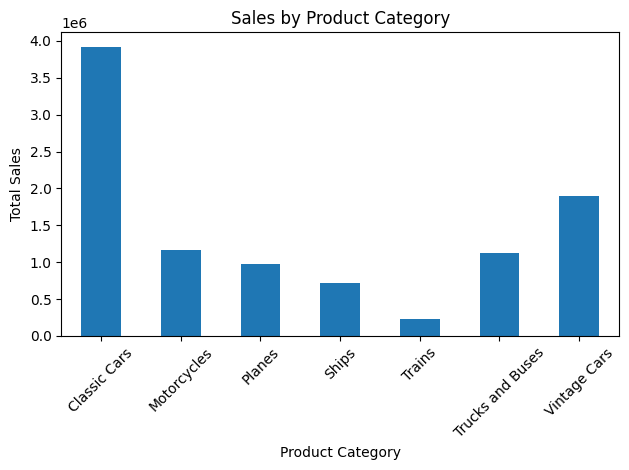

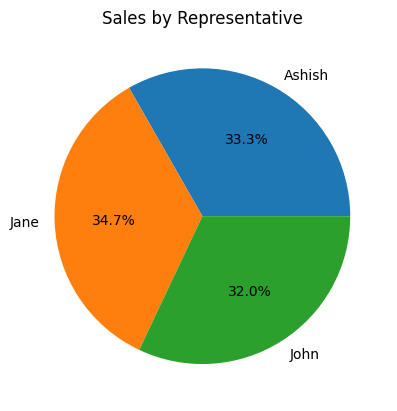

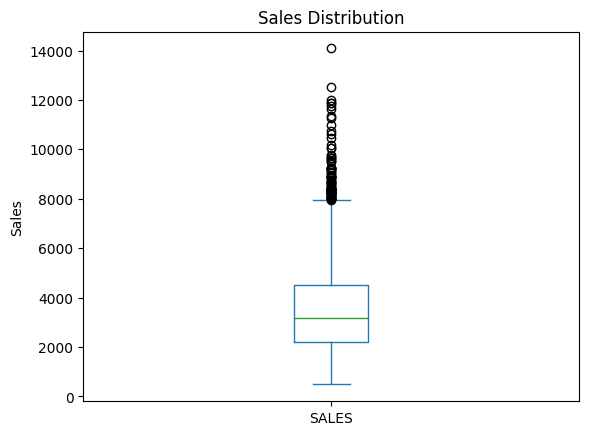

In [1]:

import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt

# 1. Load data

csv = pd.read_csv("sales_data_sample.csv", encoding="cp1252")
ed = pd.read_excel("Sample-Sales-Data.xlsx")

with open("customers.json", "r") as file:
    json_data = json.load(file)

json_df = pd.json_normalize(json_data)


# 2. Explore data

print("CSV Data")
print(csv.head())
csv.info()
print(csv.describe())

print("\nExcel Data")
print(ed.head())
ed.info()
print(ed.describe())

print("\nJSON Data")
print(json_df.head())
json_df.info()


# 3. Data Cleaning

csv = csv.drop_duplicates()
ed = ed.drop_duplicates()
json_df = json_df.drop_duplicates()

# Handle missing values
csv = csv.dropna(subset=['SALES', 'ORDERNUMBER', 'PRODUCTLINE'])
ed = ed.dropna()
json_df = json_df.dropna()


# 4. Unified format
# Keep separate DataFrames because their structures differ

print("\nCleaned CSV:", csv.shape)
print("Cleaned Excel:", ed.shape)
print("Cleaned JSON:", json_df.shape)


# 5. Data Transformation

# CSV: Create sales category
csv['Sales_Category'] = pd.cut(
    csv['SALES'],
    bins=[0, 1000, 5000, float('inf')],
    labels=['Low', 'Medium', 'High']
)

# Excel: Calculate sales representative performance
ed['Value_Category'] = pd.cut(
    ed['Value'],
    bins=[0, 30000, 70000, float('inf')],
    labels=['Low', 'Medium', 'High']
)

# JSON: Combine first and last name
json_df['Full_Name'] = (
    json_df['first'] + ' ' + json_df['last']
)


# 6. Data Analysis

total_sales = csv['SALES'].sum()
print("\nTotal Sales:", total_sales)

average_sales = csv['SALES'].mean()
print("Average Sales:", average_sales)

average_order_value = csv.groupby(
    'ORDERNUMBER'
)['SALES'].sum().mean()

print("Average Order Value:", average_order_value)

category_sales = csv.groupby(
    'PRODUCTLINE'
)['SALES'].sum()

print("\nSales by Product Category:")
print(category_sales)

rep_sales = ed.groupby(
    'Sales_Rep_Name'
)['Value'].sum()

print("\nSales by Representative:")
print(rep_sales)

customer_country = json_df['country'].value_counts()

print("\nCustomers by Country:")
print(customer_country.head())


# 7. Visualization

# Bar Plot
category_sales.plot(kind='bar')
plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Pie Chart
rep_sales.plot(kind='pie', autopct='%1.1f%%')
plt.title('Sales by Representative')
plt.ylabel('')
plt.show()

# Box Plot
csv['SALES'].plot(kind='box')
plt.title('Sales Distribution')
plt.ylabel('Sales')
plt.show()
